# O3 · Edición anterior del circuito (2025)

Descarga y limpia la edición anterior con **el mismo código** que la edición actual.
Las funciones viven en `src/` (`src/scraping.py`, `src/limpieza.py`). Aquí solo hay
**configuración por edición** y el flujo de trabajo. Ejecutar de arriba abajo.

- Fuente: `corunacorre.com`, edición 58 (2025). Todas sus carreras ya se disputaron.
- Los datos con nombres (`raw/`, `interim/`) se quedan en local: no se suben a GitHub.
- No se muestran nombres ni dorsales en ninguna salida.

In [25]:
import math
import sys
from datetime import date
from pathlib import Path

import pandas as pd

# El notebook está en notebooks/: la raíz del repositorio es la carpeta superior
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.scraping import EdicionConfig, Scraper
from src.limpieza import limpiar_resultados

## 1. Configuración por edición

Lo único que cambia entre ediciones es esta configuración.

`patron_evento` debe ser específico de cada edición: la web incluye en el menú los
enlaces a los eventos de la **edición actual** (`/web/evento/NNNN/`). Si el patrón los
aceptara, carreras de 2026 se colarían en 2025.

In [26]:
CFG_2026 = EdicionConfig(
    num_edicion=63,
    idioma="gl",
    patron_evento=r"/gl/web/evento/(\d+)",
    prefijo_carrera="carrera",
    raw_dir=RAIZ / "datos" / "raw",
    cache_eventos="eventos_edicion_63.html",
)

CFG_2025 = EdicionConfig(
    num_edicion=58,
    idioma="es",
    patron_evento=r"/es/web/resultado/evento-(\d+)",
    prefijo_carrera="ant2025_carrera",
    raw_dir=RAIZ / "datos" / "raw" / "edicion_anterior",
    cache_eventos="eventos_edicion_58_historico.html",
    etiqueta_cache="2025",
)

INTERIM_2025 = RAIZ / "datos" / "interim" / "edicion_anterior"
EXTERNOS = RAIZ / "datos" / "externos"
for d in (INTERIM_2025, EXTERNOS):
    d.mkdir(parents=True, exist_ok=True)

## 2. Descubrir las carreras (edición → evento → categoría Absoluta)

La categoría Absoluta se localiza por el **texto del enlace**, no por su posición.

In [27]:
scraper_2025 = Scraper(CFG_2025, verbose=False)
carreras_2025 = scraper_2025.descubrir_carreras_absoluta()

tabla_carreras = pd.DataFrame(carreras_2025)[
    ["id_carrera", "id_evento", "nombre", "nombre_enlace", "url_absoluta"]
]
display(tabla_carreras)
print("Carreras con categoría Absoluta:", len(carreras_2025))
print("Eventos sin Absoluta:", scraper_2025.excluidas)

,id_carrera,id_evento,nombre,nombre_enlace,url_absoluta
0,ant2025_carrera_01,2938,RESULTADOS 2025 EVENTOS Torre de Hercules,XIII CARREIRA POPULAR TORRE DE HÉRCULES -TROFE...,/es/web/resultado/competicion-15696
1,ant2025_carrera_02,2943,RESULTADOS 2025 EVENTOS Matogrande-Xuxán,IX CARREIRA POPULAR MATOGRANDE - XUXÁN,/es/web/resultado/competicion-15705
2,ant2025_carrera_03,2944,RESULTADOS 2025 EVENTOS San Pedro de Visma,XVI BAIXADA POPULAR DE CROSS SAN PEDRO DE VISMA,/es/web/resultado/competicion-15706
3,ant2025_carrera_04,2945,RESULTADOS 2025 EVENTOS Os Rosales,XII CARREIRA POPULAR OS ROSALES,/es/web/resultado/competicion-15707
4,ant2025_carrera_05,2946,RESULTADOS 2025 EVENTOS Volta a Oza,XII CARREIRA POPULAR VOLTA A OZA,/es/web/resultado/competicion-15708
5,ant2025_carrera_06,2947,RESULTADOS 2025 EVENTOS Ventorrillo,XI CARREIRA POPULAR VENTORRILLO,/es/web/resultado/competicion-15709
6,ant2025_carrera_07,2948,RESULTADOS 2025 EVENTOS Novo Mesoiro,XIII CARREIRA POPULAR NOVO MESOIRO,/es/web/resultado/competicion-15710


Carreras con categoría Absoluta: 7
Eventos sin Absoluta: []


## 3. Registro de fuentes

Edición, URLs y fecha de consulta (punto 44 de la guía). **Falta rellenar `fecha_carrera`**
copiándola de la página de cada carrera en la web.

In [28]:
fuentes = tabla_carreras.assign(
    edicion=CFG_2025.num_edicion,
    anio=2025,
    url_edicion=(f"{CFG_2025.base_url}/{CFG_2025.idioma}/web/resultado/"
                 f"edicion-{CFG_2025.num_edicion}/eventos"),
    fecha_consulta=date.today().isoformat(),
    fecha_carrera=None,  # TODO: copiar de la web
)
fuentes.to_csv(EXTERNOS / "fuentes_edicion_2025.csv", index=False)
display(fuentes[["id_carrera", "edicion", "anio", "fecha_consulta", "fecha_carrera"]])

,id_carrera,edicion,anio,fecha_consulta,fecha_carrera
0,ant2025_carrera_01,58,2025,2026-11-19,None
1,ant2025_carrera_02,58,2025,2026-11-19,None
2,ant2025_carrera_03,58,2025,2026-11-19,None
3,ant2025_carrera_04,58,2025,2026-11-19,None
4,ant2025_carrera_05,58,2025,2026-11-19,None
5,ant2025_carrera_06,58,2025,2026-11-19,None
6,ant2025_carrera_07,58,2025,2026-11-19,None


## 4. Extracción completa

Todas las páginas de cada carrera, con caché de bytes y pausa entre peticiones.
Las tablas con nombres se guardan en `datos/interim/edicion_anterior/` (local).

In [29]:
resultados, registro = [], []
for c in carreras_2025:
    df_c, n_pag = scraper_2025.extraer_carrera(c["id_carrera"], c["url_absoluta"])
    df_c.to_csv(INTERIM_2025 / f"{c['id_carrera']}_interim.csv", index=False)
    resultados.append(df_c)

    duplicados = int(df_c.duplicated(subset=["dorsal"]).sum())
    paginas_esperadas = math.ceil(len(df_c) / 25)
    registro.append({
        "id_carrera": c["id_carrera"],
        "evento_id": c["id_evento"],
        "nombre": c["nombre"],
        "paginas": n_pag,
        "participantes": len(df_c),
        "paginas_coherentes": n_pag == paginas_esperadas,
        "duplicados_dorsal": duplicados,
        "estado": "OK" if len(df_c) > 0 and duplicados == 0 and n_pag == paginas_esperadas else "REVISAR",
    })

df_anterior = pd.concat(resultados, ignore_index=True)
df_anterior.to_csv(INTERIM_2025 / "resultados_edicion_2025.csv", index=False)

df_registro = pd.DataFrame(registro)
df_registro.to_csv(INTERIM_2025 / "registro_extraccion.csv", index=False)
display(df_registro)
print("Total participaciones:", len(df_anterior))

,id_carrera,evento_id,nombre,paginas,participantes,paginas_coherentes,duplicados_dorsal,estado
0,ant2025_carrera_01,2938,RESULTADOS 2025 EVENTOS Torre de Hercules,63,1562,True,0,OK
1,ant2025_carrera_02,2943,RESULTADOS 2025 EVENTOS Matogrande-Xuxán,38,930,True,0,OK
2,ant2025_carrera_03,2944,RESULTADOS 2025 EVENTOS San Pedro de Visma,26,646,True,0,OK
3,ant2025_carrera_04,2945,RESULTADOS 2025 EVENTOS Os Rosales,32,798,True,0,OK
4,ant2025_carrera_05,2946,RESULTADOS 2025 EVENTOS Volta a Oza,27,653,True,0,OK
5,ant2025_carrera_06,2947,RESULTADOS 2025 EVENTOS Ventorrillo,29,701,True,0,OK
6,ant2025_carrera_07,2948,RESULTADOS 2025 EVENTOS Novo Mesoiro,23,567,True,0,OK


Total participaciones: 5857


In [30]:
# Control de regresión: mismas cifras que la primera versión de este notebook
ESPERADO_2025 = [1562, 930, 646, 798, 653, 701, 567]
obtenido = df_registro["participantes"].tolist()
assert obtenido == ESPERADO_2025, f"Cambian los recuentos: {obtenido}"
assert df_registro["estado"].eq("OK").all(), "Hay carreras por revisar"
print("Recuentos por carrera iguales a los esperados:", sum(obtenido), "participaciones")

Recuentos por carrera iguales a los esperados: 5857 participaciones


## 5. Limpieza equivalente a la edición actual

`limpiar_resultados` replica el notebook 02 (Persona 2): puestos compuestos separados,
tiempos a segundos con `estado_tiempo`, categoría `NO` conservada y sexo vacío cuando
la web no lo da. No se elimina ninguna fila.

In [31]:
df25 = pd.read_csv(INTERIM_2025 / "resultados_edicion_2025.csv",
                   dtype=str, keep_default_na=False)
limpias_2025 = limpiar_resultados(df25)
limpias_2025.to_csv(INTERIM_2025 / "resultados_limpios_local_2025.csv", index=False)

control = limpias_2025.assign(
    categoria_NO=limpias_2025["categoria"].eq("NO").fillna(False),
    sexo_sin_dato=limpias_2025["sexo"].isna(),
)
display(control.groupby("id_carrera")[["categoria_NO", "sexo_sin_dato"]].sum())
display(
    limpias_2025.groupby("id_carrera")["estado_tiempo"]
    .value_counts().unstack(fill_value=0)
)
print("Filas conservadas:", len(limpias_2025), "de", len(df25))

,categoria_NO,sexo_sin_dato
id_carrera,,
ant2025_carrera_01,4,4
ant2025_carrera_02,3,3
ant2025_carrera_03,4,4
ant2025_carrera_04,3,3
ant2025_carrera_05,6,6
ant2025_carrera_06,3,3
ant2025_carrera_07,1,1


estado_tiempo,revisar,valido
id_carrera,,
ant2025_carrera_01,0,1562
ant2025_carrera_02,0,930
ant2025_carrera_03,0,646
ant2025_carrera_04,0,798
ant2025_carrera_05,6,647
ant2025_carrera_06,0,701
ant2025_carrera_07,0,567


Filas conservadas: 5857 de 5857


## 6. Comprobación: el código de `src/` reproduce el notebook 01

Se ejecuta la **edición actual** con la misma función y se comparan los recuentos con
los de los notebooks 01 y 02. Usa la caché ya descargada en `datos/raw/` y **no escribe
ningún fichero**.

In [32]:
COMPROBAR_EQUIVALENCIA_CON_01 = True

if COMPROBAR_EQUIVALENCIA_CON_01:
    scraper_2026 = Scraper(CFG_2026, verbose=False)
    carreras_2026 = scraper_2026.descubrir_carreras_absoluta()
    filas_2026 = [len(scraper_2026.extraer_carrera(c["id_carrera"], c["url_absoluta"])[0])
                  for c in carreras_2026]

    ESPERADO_2026 = [1489, 929, 795, 875, 659, 643]  # notebooks 01 y 02
    assert filas_2026 == ESPERADO_2026, f"No coincide con el 01: {filas_2026}"
    print("OK: reproduce los recuentos de la edición actual", filas_2026)

    # Emparejamiento de carreras por nombre corto (revisar a mano)
    t26 = pd.DataFrame({"nombre": [c["nombre"] for c in carreras_2026],
                        "id_2026": [c["id_carrera"] for c in carreras_2026],
                        "participaciones_2026": filas_2026})
    t25 = df_registro[["nombre", "id_carrera", "participantes"]].rename(
        columns={"id_carrera": "id_2025", "participantes": "participaciones_2025"})
    display(t25.merge(t26, on="nombre", how="outer"))

OK: reproduce los recuentos de la edición actual [1489, 929, 795, 875, 659, 643]


,nombre,id_2025,participaciones_2025,id_2026,participaciones_2026
0,RESULTADOS 2025 EVENTOS Matogrande-Xuxán,ant2025_carrera_02,930.0,NaN,NaN
1,RESULTADOS 2025 EVENTOS Novo Mesoiro,ant2025_carrera_07,567.0,NaN,NaN
2,RESULTADOS 2025 EVENTOS Os Rosales,ant2025_carrera_04,798.0,NaN,NaN
3,RESULTADOS 2025 EVENTOS San Pedro de Visma,ant2025_carrera_03,646.0,NaN,NaN
4,RESULTADOS 2025 EVENTOS Torre de Hercules,ant2025_carrera_01,1562.0,NaN,NaN
5,RESULTADOS 2025 EVENTOS Ventorrillo,ant2025_carrera_06,701.0,NaN,NaN
6,RESULTADOS 2025 EVENTOS Volta a Oza,ant2025_carrera_05,653.0,NaN,NaN
7,RESULTADOS ACTUAL EVENTOS Matogrande-Xuxán,NaN,NaN,carrera_02,929.0
8,RESULTADOS ACTUAL EVENTOS Os Rosales,NaN,NaN,carrera_04,875.0
9,RESULTADOS ACTUAL EVENTOS San Pedro de Visma,NaN,NaN,carrera_03,795.0


In [37]:
import re

# Si las fechas están en los HTML cacheados de datos/raw/edicion_anterior/, las intentamos detectar;
# si alguna queda en None, rellénala a mano con formato "YYYY-MM-DD" desde corunacorre.com.
FECHAS_2025 = {
    "ant2025_carrera_01": None,  # Torre de Hércules 2025
    "ant2025_carrera_02": None,  # Matogrande - Xuxán 2025
    "ant2025_carrera_03": None,  # San Pedro de Visma 2025
    "ant2025_carrera_04": None,  # Os Rosales 2025
    "ant2025_carrera_05": None,  # Volta a Oza 2025
    "ant2025_carrera_06": None,  # Ventorrillo 2025
    "ant2025_carrera_07": None,  # Novo Mesoiro 2025
}

# Búsqueda opcional en la caché HTML local para ahorrarte mirar una a una
raw_2025 = CFG_2025.raw_dir
for cid in FECHAS_2025:
    if FECHAS_2025[cid] is not None:
        continue
    htmls = sorted(raw_2025.glob(f"*{cid}*"))
    for h in htmls:
        texto = h.read_text(encoding="utf-8", errors="ignore")
        m = re.search(r"(\d{2})/(\d{2})/2025", texto)
        if m:
            FECHAS_2025[cid] = f"2025-{m.group(2)}-{m.group(1)}"
            break

fuentes["fecha_carrera"] = fuentes["id_carrera"].map(FECHAS_2025)
fuentes.to_csv(EXTERNOS / "fuentes_edicion_2025.csv", index=False)
display(fuentes[["id_carrera", "nombre", "fecha_carrera"]])

,id_carrera,nombre,fecha_carrera
0,ant2025_carrera_01,RESULTADOS 2025 EVENTOS Torre de Hercules,None
1,ant2025_carrera_02,RESULTADOS 2025 EVENTOS Matogrande-Xuxán,None
2,ant2025_carrera_03,RESULTADOS 2025 EVENTOS San Pedro de Visma,None
3,ant2025_carrera_04,RESULTADOS 2025 EVENTOS Os Rosales,None
4,ant2025_carrera_05,RESULTADOS 2025 EVENTOS Volta a Oza,None
5,ant2025_carrera_06,RESULTADOS 2025 EVENTOS Ventorrillo,None
6,ant2025_carrera_07,RESULTADOS 2025 EVENTOS Novo Mesoiro,None


In [34]:
import hashlib
import hmac
import numpy as np
import matplotlib.pyplot as plt

# Cargamos los datos limpios de 2026 (generados en 02 y 02b)
participacions_2026 = pd.read_csv(RAIZ / "datos" / "clean" / "participacions.csv")
carreiras_2026 = pd.read_csv(RAIZ / "datos" / "clean" / "carreiras.csv")

# Mapa de correspondencia explícita entre las 6 carreras comparables
MAPA_COMPARABLES = {
    "ant2025_carrera_01": ("carrera_01", "Torre de Hércules"),
    "ant2025_carrera_02": ("carrera_02", "Matogrande-Xuxán"),
    "ant2025_carrera_03": ("carrera_03", "San Pedro de Visma"),
    "ant2025_carrera_04": ("carrera_04", "Os Rosales"),
    "ant2025_carrera_05": ("carrera_05", "Volta a Oza"),
    "ant2025_carrera_06": ("carrera_06", "Ventorrillo"),
    # ant2025_carrera_07 (Novo Mesoiro) queda fuera de las comparables 1 a 1
}

df25_comp = limpias_2025[limpias_2025["id_carrera"].isin(MAPA_COMPARABLES)].copy()
df25_comp["prueba"] = df25_comp["id_carrera"].map(lambda x: MAPA_COMPARABLES[x][1])
df25_comp["edicion_anio"] = 2025

mapa_26 = {v[0]: v[1] for v in MAPA_COMPARABLES.values()}
df26_comp = participacions_2026[participacions_2026["id_carrera"].isin(mapa_26)].copy()
df26_comp["prueba"] = df26_comp["id_carrera"].map(mapa_26)
df26_comp["edicion_anio"] = 2026

ambas = pd.concat([df25_comp, df26_comp], ignore_index=True)
print(f"Participaciones en las 6 pruebas comparables -> 2025: {len(df25_comp)} | 2026: {len(df26_comp)}")

Participaciones en las 6 pruebas comparables -> 2025: 5290 | 2026: 5390


edicion_anio       2025           2026          
sexo                  F    M <NA>    F    M <NA>
prueba                                          
Matogrande-Xuxán    309  618    3  294  629    6
Os Rosales          255  540    3  298  577    0
San Pedro de Visma  207  435    4  237  553    5
Torre de Hércules   622  936    4  558  928    3
Ventorrillo         213  485    3  184  459    0
Volta a Oza         188  459    6  189  467    3

Porcentaje de participación femenina (%) en pruebas comparables:


edicion_anio,2025,2026,dif_pp_26_vs_25
prueba,,,
Matogrande-Xuxán,33.33,31.85,-1.48
Os Rosales,32.08,34.06,1.98
San Pedro de Visma,32.24,30.00,-2.24
Torre de Hércules,39.92,37.55,-2.37
Ventorrillo,30.52,28.62,-1.90
Volta a Oza,29.06,28.81,-0.25


edicion_anio 2025       2026     
sexo            F     M    F    M
categoria                        
ESP             2     2    1    2
MS1           392   900  432  950
MS2           352   853  391  937
MS3           109   409  107  483
MS4            27   142   35  110
SNR           809  1014  685  982
SUB20          22    52   27   45
SUB23          81   101   82  104

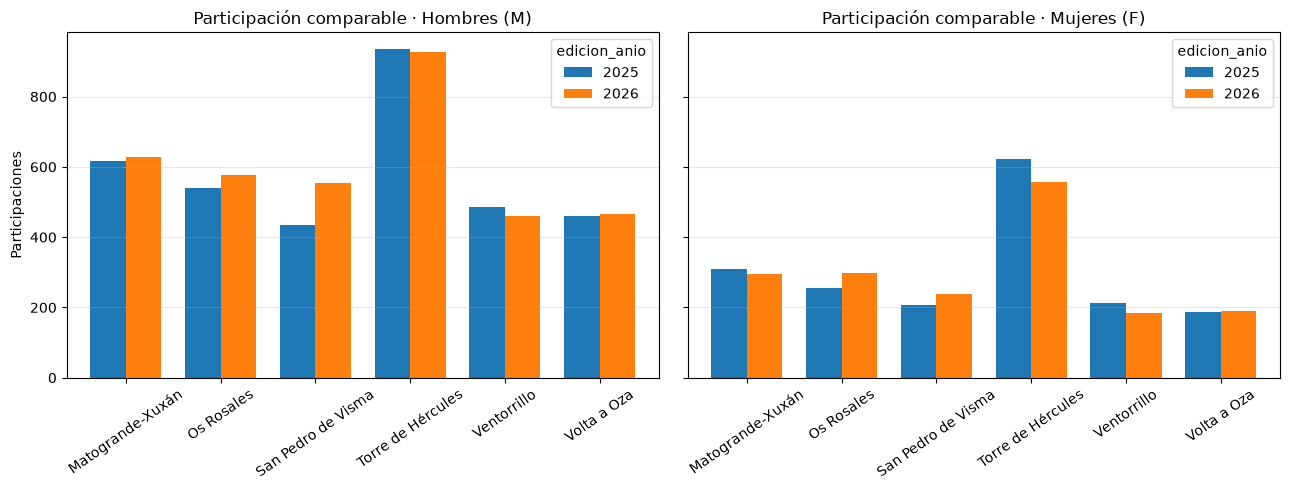

In [35]:
# 1) Participación total y por sexo en cada prueba comparable
comp_sexo = (
    ambas.groupby(["prueba", "edicion_anio", "sexo"], dropna=False)
    .size()
    .unstack(["edicion_anio", "sexo"], fill_value=0)
)
display(comp_sexo)

# Porcentaje femenino por prueba y año
solo_mf = ambas[ambas["sexo"].isin(["F", "M"])]
pct_f = (
    solo_mf.groupby(["prueba", "edicion_anio"])["sexo"]
    .apply(lambda s: (s == "F").mean() * 100)
    .unstack()
    .round(2)
)
pct_f["dif_pp_26_vs_25"] = (pct_f[2026] - pct_f[2025]).round(2)
print("Porcentaje de participación femenina (%) en pruebas comparables:")
display(pct_f)

# 2) Distribución por categoría y sexo (2025 vs 2026)
comp_cat = (
    solo_mf.groupby(["categoria", "edicion_anio", "sexo"])
    .size()
    .unstack(["edicion_anio", "sexo"], fill_value=0)
)
display(comp_cat)

# Gráfico comparativo por prueba y sexo
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, sexo_cod, titulo in zip(axes, ["M", "F"], ["Hombres (M)", "Mujeres (F)"]):
    datos_plot = (
        solo_mf[solo_mf["sexo"] == sexo_cod]
        .groupby(["prueba", "edicion_anio"])
        .size()
        .unstack(fill_value=0)
    )
    datos_plot.plot(kind="bar", ax=ax, width=0.75)
    ax.set_title(f"Participación comparable · {titulo}")
    ax.set_xlabel("")
    ax.set_ylabel("Participaciones")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
archivo_env = RAIZ / ".env"
assert archivo_env.is_file(), "Falta el archivo .env en la raíz del repositorio."

variables = dict(
    linea.split("=", 1)
    for linea in archivo_env.read_text(encoding="utf-8").splitlines()
    if "=" in linea and not linea.lstrip().startswith("#")
)
clave_hmac = variables.get("CORUNA_HMAC_KEY", "").strip().encode("utf-8")
assert clave_hmac, "Falta CORUNA_HMAC_KEY en .env."

def normalizar_nombre(columna: pd.Series) -> pd.Series:
    return (
        columna.fillna("")
        .str.normalize("NFKD")
        .str.replace(r"[\u0300-\u036f]", "", regex=True)
        .str.upper()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

def hmac_nombre(nombre_norm: str) -> str:
    return hmac.new(
        clave_hmac,
        f"nombre:{nombre_norm}".encode("utf-8"),
        hashlib.sha256,
    ).hexdigest()[:12]

# Cargamos resultados limpios locales de ambos años (ambos tienen nombre_completo en local)
loc_2025 = pd.read_csv(INTERIM_2025 / "resultados_limpios_local_2025.csv", dtype=str, keep_default_na=False)
loc_2026 = pd.read_csv(RAIZ / "datos" / "interim" / "resultados_limpios_local.csv", dtype=str, keep_default_na=False)

for df_loc in (loc_2025, loc_2026):
    norm = normalizar_nombre(df_loc["nombre_completo"])
    df_loc["hmac_nombre"] = norm.map(hmac_nombre)
    # Descartamos nombres vacíos o duplicados dentro de la misma carrera (posibles homónimos)
    dup_carrera = df_loc.duplicated(["id_carrera", "hmac_nombre"], keep=False)
    df_loc["hmac_valido"] = norm.ne("") & ~dup_carrera

personas_2025 = set(loc_2025.loc[loc_2025["hmac_valido"], "hmac_nombre"])
personas_2026 = set(loc_2026.loc[loc_2026["hmac_valido"], "hmac_nombre"])
repetidores = personas_2025 & personas_2026

print(f"Personas únicas identificadas en 2025 (7 carreras): {len(personas_2025)}")
print(f"Personas únicas identificadas en 2026 (6 carreras): {len(personas_2026)}")
print(f"Personas que repiten en 2026 respecto a 2025: {len(repetidores)} "
      f"({len(repetidores) / len(personas_2025) * 100:.1f}% de las de 2025 | "
      f"{len(repetidores) / len(personas_2026) * 100:.1f}% de las de 2026)")

# Tasa de repetición según tipo de inscripción en 2026
loc_2026_cruce = loc_2026.merge(
    participacions_2026[["id_carrera", "puesto_general", "tipo_inscripcion"]].assign(
        puesto_general=lambda d: d["puesto_general"].astype("Int64").astype(str)
    ),
    on=["id_carrera", "puesto_general"],
    how="left",
)
loc_2026_cruce["repitio_2025"] = loc_2026_cruce["hmac_nombre"].isin(repetidores)
display(
    loc_2026_cruce.groupby("tipo_inscripcion")["repitio_2025"]
    .agg(participaciones="count", de_repetidores="sum", pct_repetidores=lambda s: round(s.mean() * 100, 2))
)

Personas únicas identificadas en 2025 (7 carreras): 2677
Personas únicas identificadas en 2026 (6 carreras): 2419
Personas que repiten en 2026 respecto a 2025: 1009 (37.7% de las de 2025 | 41.7% de las de 2026)


,participaciones,de_repetidores,pct_repetidores
tipo_inscripcion,,,
inscrito_circuito,3833,2542,66.32
no_resuelto,99,39,39.39
por_prueba,1458,361,24.76
